# TA-05: Implementasi Decision Tree untuk Klasifikasi Penyakit Jantung
**Mata Praktikum:** Pembelajaran Mesin | **Modul 05:** Algoritma Decision Tree

Notebook ini adalah kelanjutan TP-05. Dataset: *Heart Failure Prediction Dataset* (Soriano, 2021) - https://www.kaggle.com/datasets/fedesoriano/heart-failure-prediction

**Cara pakai di Google Colab:** unggah `heart.csv` ke panel Files, lalu jalankan semua sel (Runtime > Run all).

## 1. Persiapan Library dan Data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import (classification_report, confusion_matrix, accuracy_score,
                             roc_curve, roc_auc_score)

sns.set_theme(style="whitegrid")

df = pd.read_csv("data/heart.csv")
print("Ukuran dataset:", df.shape)
df.head()

Ukuran dataset: (918, 12)


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


In [2]:
df.info()
print("\nNilai kosong (NaN) per kolom:")
print(df.isna().sum())
print("\nData duplikat:", df.duplicated().sum())
df.describe().T

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    object 
 2   ChestPainType   918 non-null    object 
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    object 
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    object 
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    object 
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), object(5)
memory usage: 86.2+ KB

Nilai kosong (NaN) per kolom:
Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAng

,count,mean,std,min,25%,50%,75%,max
Age,918.0,53.510893,9.432617,28.0,47.00,54.0,60.0,77.0
RestingBP,918.0,132.396514,18.514154,0.0,120.00,130.0,140.0,200.0
Cholesterol,918.0,198.799564,109.384145,0.0,173.25,223.0,267.0,603.0
FastingBS,918.0,0.233115,0.423046,0.0,0.00,0.0,0.0,1.0
MaxHR,918.0,136.809368,25.460334,60.0,120.00,138.0,156.0,202.0
Oldpeak,918.0,0.887364,1.066570,-2.6,0.00,0.6,1.5,6.2
HeartDisease,918.0,0.553377,0.497414,0.0,0.00,1.0,1.0,1.0


## 2. Eksplorasi Data (EDA)

### 2.1 Distribusi variabel target

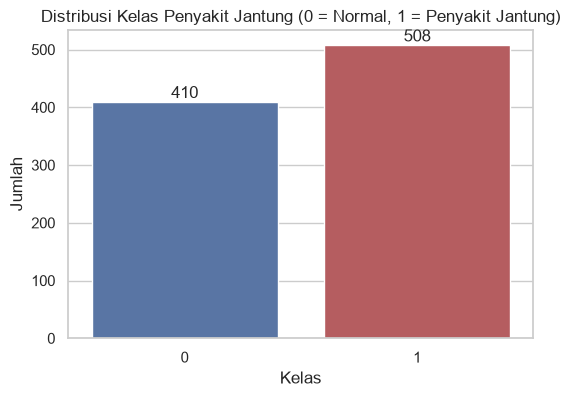

HeartDisease
1    0.553
0    0.447
Name: proportion, dtype: float64


In [3]:
plt.figure(figsize=(6, 4))
ax = sns.countplot(x="HeartDisease", data=df, hue="HeartDisease",
                   palette=["#4C72B0", "#C44E52"], legend=False)
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom")
plt.title("Distribusi Kelas Penyakit Jantung (0 = Normal, 1 = Penyakit Jantung)")
plt.xlabel("Kelas"); plt.ylabel("Jumlah")
plt.show()
print(df["HeartDisease"].value_counts(normalize=True).round(3))

### 2.2 Nilai hilang tersembunyi
Pada dataset ini nilai kosong ditulis sebagai angka **0**. Kolesterol dan tekanan darah istirahat bernilai 0 tidak mungkin terjadi secara medis, sehingga nilai tersebut dianggap *missing value*.

In [4]:
print("Cholesterol = 0 :", (df["Cholesterol"] == 0).sum(), "baris")
print("RestingBP   = 0 :", (df["RestingBP"] == 0).sum(), "baris")
print("\nCholesterol = 0 per kelas target:")
print(df[df["Cholesterol"] == 0]["HeartDisease"].value_counts())

Cholesterol = 0 : 172 baris
RestingBP   = 0 : 1 baris

Cholesterol = 0 per kelas target:
HeartDisease
1    152
0     20
Name: count, dtype: int64


### 2.3 Hubungan fitur numerik dengan target

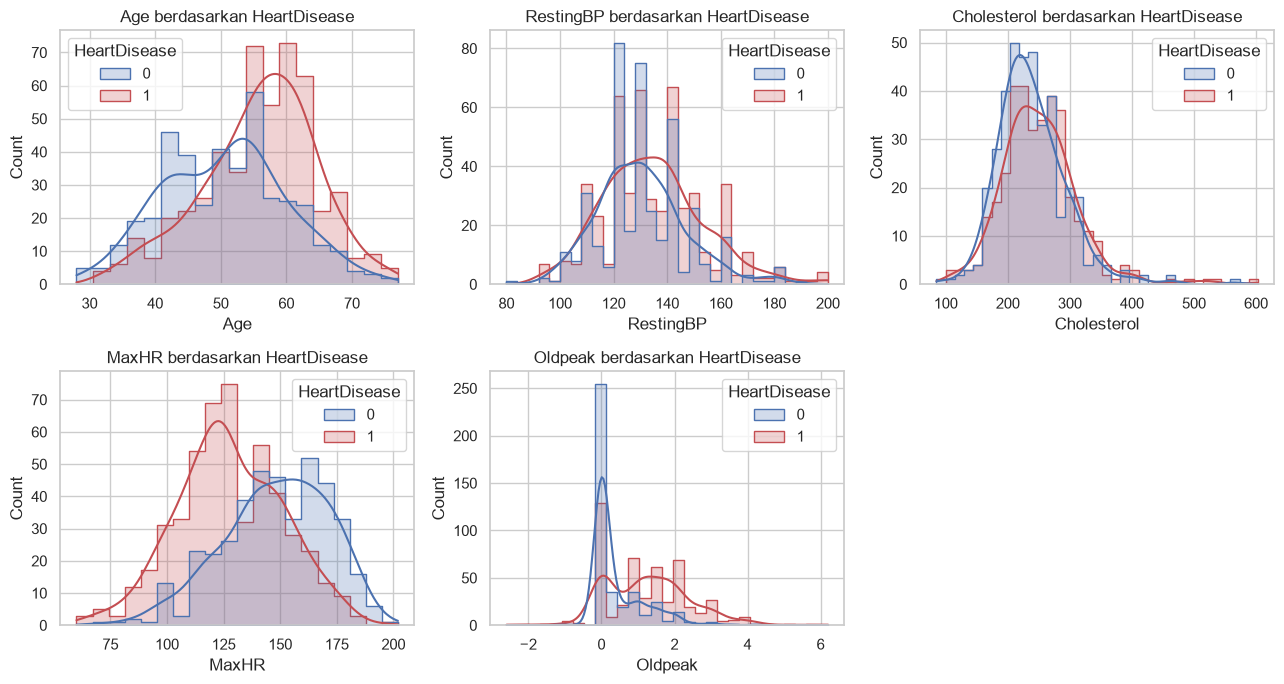

In [5]:
num_cols = ["Age", "RestingBP", "Cholesterol", "MaxHR", "Oldpeak"]
d = df.copy()
d["Cholesterol"] = d["Cholesterol"].replace(0, np.nan)
d["RestingBP"] = d["RestingBP"].replace(0, np.nan)

fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, c in zip(axes.ravel(), num_cols):
    sns.histplot(data=d, x=c, hue="HeartDisease", kde=True,
                 palette=["#4C72B0", "#C44E52"], ax=ax, element="step")
    ax.set_title(f"{c} berdasarkan HeartDisease")
axes.ravel()[-1].axis("off")
plt.tight_layout(); plt.show()

### 2.4 Hubungan fitur kategorikal dengan target

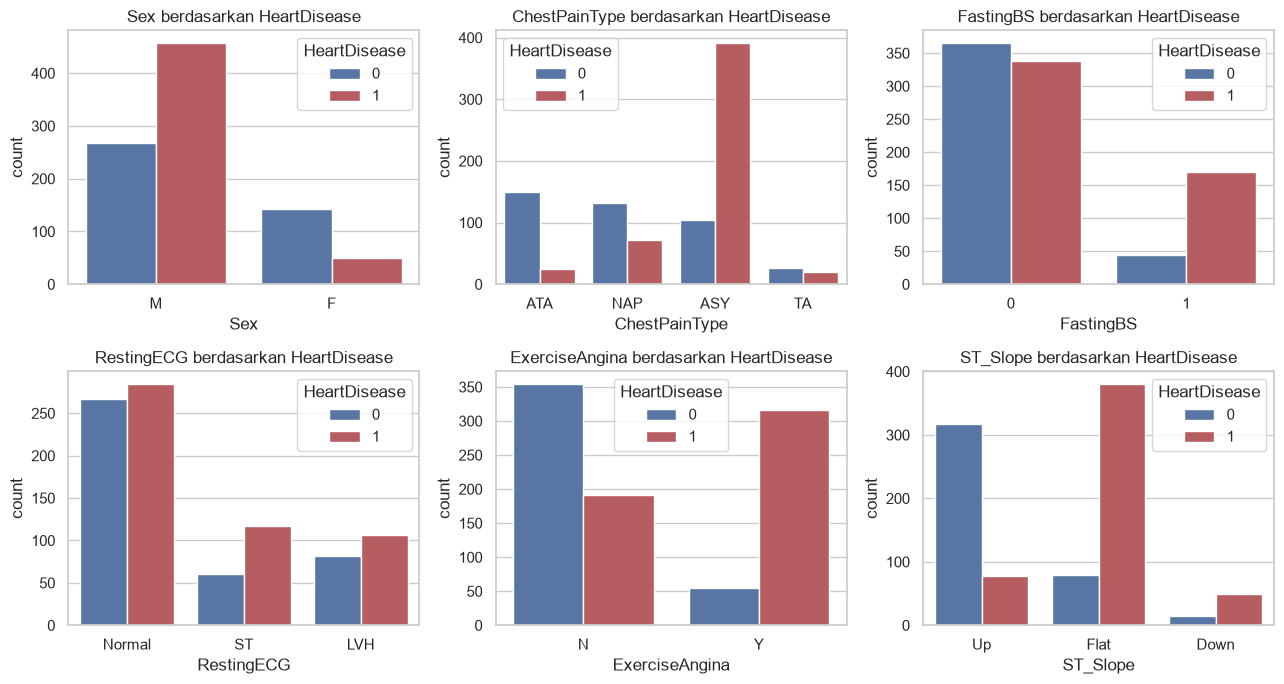


Proporsi penyakit jantung per Sex:
Sex
F    0.26
M    0.63
Name: HeartDisease, dtype: float64

Proporsi penyakit jantung per ChestPainType:
ChestPainType
ASY    0.79
ATA    0.14
NAP    0.35
TA     0.43
Name: HeartDisease, dtype: float64

Proporsi penyakit jantung per FastingBS:
FastingBS
0    0.48
1    0.79
Name: HeartDisease, dtype: float64

Proporsi penyakit jantung per RestingECG:
RestingECG
LVH       0.56
Normal    0.52
ST        0.66
Name: HeartDisease, dtype: float64

Proporsi penyakit jantung per ExerciseAngina:
ExerciseAngina
N    0.35
Y    0.85
Name: HeartDisease, dtype: float64

Proporsi penyakit jantung per ST_Slope:
ST_Slope
Down    0.78
Flat    0.83
Up      0.20
Name: HeartDisease, dtype: float64


In [6]:
cat_cols = ["Sex", "ChestPainType", "FastingBS", "RestingECG", "ExerciseAngina", "ST_Slope"]
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, c in zip(axes.ravel(), cat_cols):
    sns.countplot(data=df, x=c, hue="HeartDisease", palette=["#4C72B0", "#C44E52"], ax=ax)
    ax.set_title(f"{c} berdasarkan HeartDisease")
plt.tight_layout(); plt.show()

for c in cat_cols:
    print(f"\nProporsi penyakit jantung per {c}:")
    print(df.groupby(c)["HeartDisease"].mean().round(2))

### 2.5 Korelasi fitur numerik

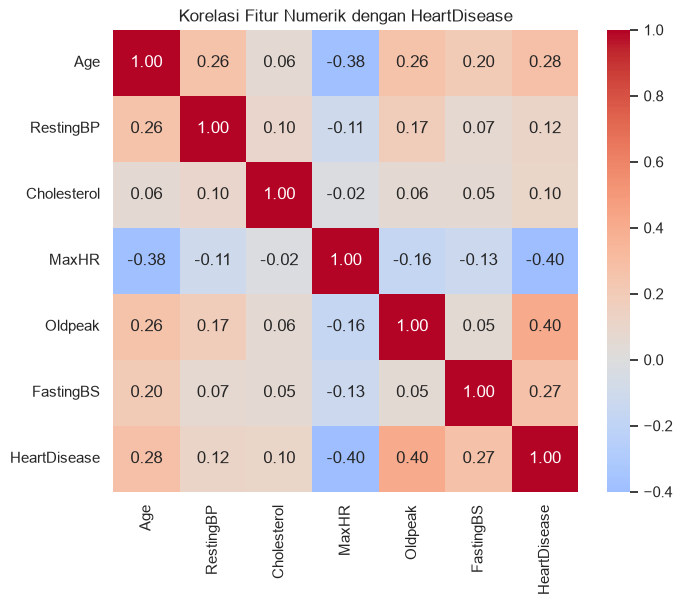

In [7]:
corr = d[num_cols + ["FastingBS", "HeartDisease"]].corr()
plt.figure(figsize=(7.5, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Korelasi Fitur Numerik dengan HeartDisease")
plt.show()

## 3. Pra-pemrosesan Data
Langkah yang dilakukan:
1. **Missing value:** nilai 0 pada `Cholesterol` dan `RestingBP` diubah menjadi `NaN`, lalu diisi dengan **median** (`SimpleImputer`).
2. **Fitur kategorikal:** diubah menjadi angka dengan **One-Hot Encoding** (`OneHotEncoder`).
3. Imputasi dan encoding dibungkus dalam `Pipeline` sehingga median dihitung **hanya dari data latih** (mencegah *data leakage*) dan model dapat dipakai langsung pada aplikasi Flask.

In [8]:
df2 = df.copy()
df2["Cholesterol"] = df2["Cholesterol"].replace(0, np.nan)
df2["RestingBP"] = df2["RestingBP"].replace(0, np.nan)
print(df2.isna().sum()[lambda s: s > 0])

X = df2.drop(columns="HeartDisease")
y = df2["HeartDisease"]

num_feats = ["Age", "RestingBP", "Cholesterol", "FastingBS", "MaxHR", "Oldpeak"]
cat_feats = ["Sex", "ChestPainType", "RestingECG", "ExerciseAngina", "ST_Slope"]

def make_prep():
    return ColumnTransformer([
        ("num", SimpleImputer(strategy="median"), num_feats),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_feats),
    ])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y)
print("Data latih:", X_train.shape, "| Data uji:", X_test.shape)

RestingBP        1
Cholesterol    172
dtype: int64
Data latih: (642, 11) | Data uji: (276, 11)


## 4. Pengembangan Model
- **Model A (potensi overfit):** `max_depth=None`, pohon tumbuh tanpa batas.
- **Model B (di-pruning):** `max_depth` dibatasi (3 atau 4).

In [9]:
def build(depth, **kw):
    return Pipeline([("prep", make_prep()),
                     ("clf", DecisionTreeClassifier(max_depth=depth, random_state=42, **kw))])

modelA = build(None).fit(X_train, y_train)
clfA = modelA.named_steps["clf"]
print(f"Model A -> kedalaman pohon: {clfA.get_depth()}, jumlah daun: {clfA.get_n_leaves()}")

Model A -> kedalaman pohon: 12, jumlah daun: 100


### 4.1 Memilih nilai `max_depth` untuk Model B
Kita bandingkan akurasi data latih, data uji, dan *cross-validation* 5-fold (dihitung hanya pada data latih) untuk berbagai kedalaman.

,max_depth,akurasi_latih,akurasi_uji,akurasi_cv
0,1,0.818,0.804,0.818
1,2,0.818,0.804,0.818
2,3,0.850,0.855,0.822
3,4,0.860,0.859,0.804
4,5,0.889,0.826,0.799
5,6,0.908,0.819,0.801
6,7,0.936,0.815,0.804
7,8,0.952,0.815,0.791
8,9,0.977,0.797,0.779
9,10,0.989,0.801,0.779


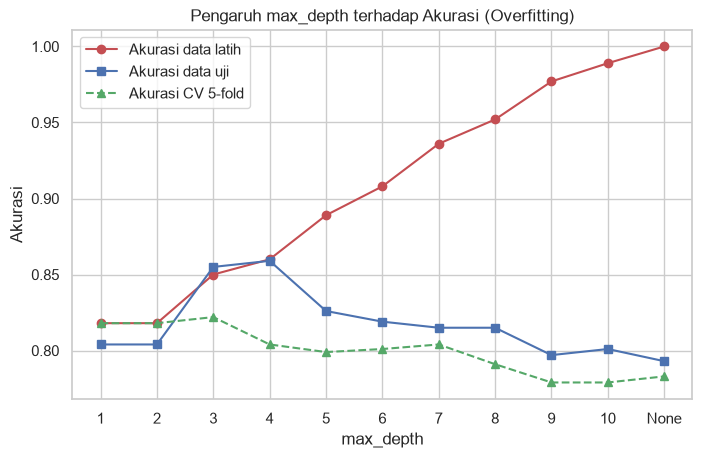

In [10]:
cv = StratifiedKFold(5, shuffle=True, random_state=42)
rows = []
for dpt in list(range(1, 11)) + [None]:
    m = build(dpt).fit(X_train, y_train)
    rows.append({"max_depth": "None" if dpt is None else dpt,
                 "akurasi_latih": accuracy_score(y_train, m.predict(X_train)),
                 "akurasi_uji": accuracy_score(y_test, m.predict(X_test)),
                 "akurasi_cv": cross_val_score(build(dpt), X_train, y_train, cv=cv).mean()})
curve = pd.DataFrame(rows).round(3)
display(curve)

plt.figure(figsize=(8, 4.8))
xs = range(len(curve))
plt.plot(xs, curve.akurasi_latih, "o-", label="Akurasi data latih", color="#C44E52")
plt.plot(xs, curve.akurasi_uji, "s-", label="Akurasi data uji", color="#4C72B0")
plt.plot(xs, curve.akurasi_cv, "^--", label="Akurasi CV 5-fold", color="#55A868")
plt.xticks(xs, curve.max_depth.astype(str))
plt.xlabel("max_depth"); plt.ylabel("Akurasi")
plt.title("Pengaruh max_depth terhadap Akurasi (Overfitting)")
plt.legend(); plt.show()

In [11]:
# Pilih max_depth 3 atau 4 dengan akurasi CV tertinggi
cv_by_depth = curve.set_index("max_depth")["akurasi_cv"]
best_depth = 3 if cv_by_depth[3] >= cv_by_depth[4] else 4
print("max_depth terpilih untuk Model B:", best_depth)

modelB = build(best_depth).fit(X_train, y_train)
clfB = modelB.named_steps["clf"]
print(f"Model B -> kedalaman pohon: {clfB.get_depth()}, jumlah daun: {clfB.get_n_leaves()}")

max_depth terpilih untuk Model B: 3
Model B -> kedalaman pohon: 3, jumlah daun: 8


## 5. Evaluasi dan Perbandingan Model A vs Model B

In [12]:
for nama, m in [("Model A (max_depth=None)", modelA), (f"Model B (max_depth={best_depth})", modelB)]:
    pred = m.predict(X_test)
    print("=" * 60)
    print(nama)
    print("Akurasi data latih:", round(accuracy_score(y_train, m.predict(X_train)), 4))
    print("Akurasi data uji  :", round(accuracy_score(y_test, pred), 4))
    print("AUC data uji      :", round(roc_auc_score(y_test, m.predict_proba(X_test)[:, 1]), 4))
    print("\n--- Confusion Matrix ---")
    print(confusion_matrix(y_test, pred))
    print("\n--- Classification Report ---")
    print(classification_report(y_test, pred, target_names=["Normal", "Penyakit Jantung"]))

Model A (max_depth=None)
Akurasi data latih: 1.0
Akurasi data uji  : 0.7935
AUC data uji      : 0.7962

--- Confusion Matrix ---
[[101  22]
 [ 35 118]]

--- Classification Report ---
                  precision    recall  f1-score   support

          Normal       0.74      0.82      0.78       123
Penyakit Jantung       0.84      0.77      0.81       153

        accuracy                           0.79       276
       macro avg       0.79      0.80      0.79       276
    weighted avg       0.80      0.79      0.79       276

Model B (max_depth=3)
Akurasi data latih: 0.8505
Akurasi data uji  : 0.8551
AUC data uji      : 0.9147

--- Confusion Matrix ---
[[108  15]
 [ 25 128]]

--- Classification Report ---
                  precision    recall  f1-score   support

          Normal       0.81      0.88      0.84       123
Penyakit Jantung       0.90      0.84      0.86       153

        accuracy                           0.86       276
       macro avg       0.85      0.86      0.85  

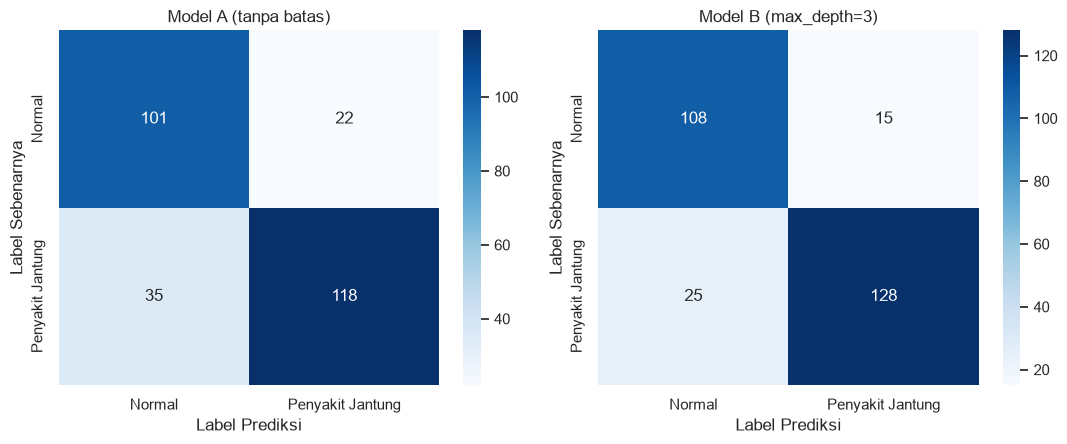

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
for ax, m, t in zip(axes, [modelA, modelB],
                    ["Model A (tanpa batas)", f"Model B (max_depth={best_depth})"]):
    sns.heatmap(confusion_matrix(y_test, m.predict(X_test)), annot=True, fmt="d", cmap="Blues", ax=ax,
                xticklabels=["Normal", "Penyakit Jantung"], yticklabels=["Normal", "Penyakit Jantung"])
    ax.set_title(t); ax.set_xlabel("Label Prediksi"); ax.set_ylabel("Label Sebenarnya")
plt.tight_layout(); plt.show()

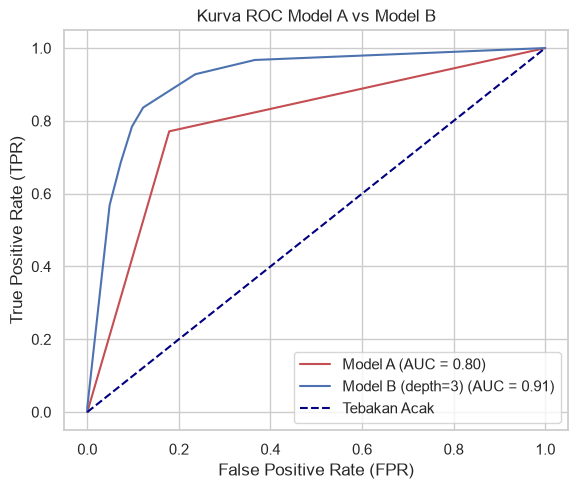

In [14]:
plt.figure(figsize=(6.5, 5.2))
for m, lab, col in [(modelA, "Model A", "#C44E52"), (modelB, f"Model B (depth={best_depth})", "#4C72B0")]:
    proba = m.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, proba)
    plt.plot(fpr, tpr, label=f"{lab} (AUC = {roc_auc_score(y_test, proba):.2f})", color=col)
plt.plot([0, 1], [0, 1], "--", color="navy", label="Tebakan Acak")
plt.xlabel("False Positive Rate (FPR)"); plt.ylabel("True Positive Rate (TPR)")
plt.title("Kurva ROC Model A vs Model B"); plt.legend(); plt.grid(True); plt.show()

## 6. Visualisasi dan Interpretasi Model B

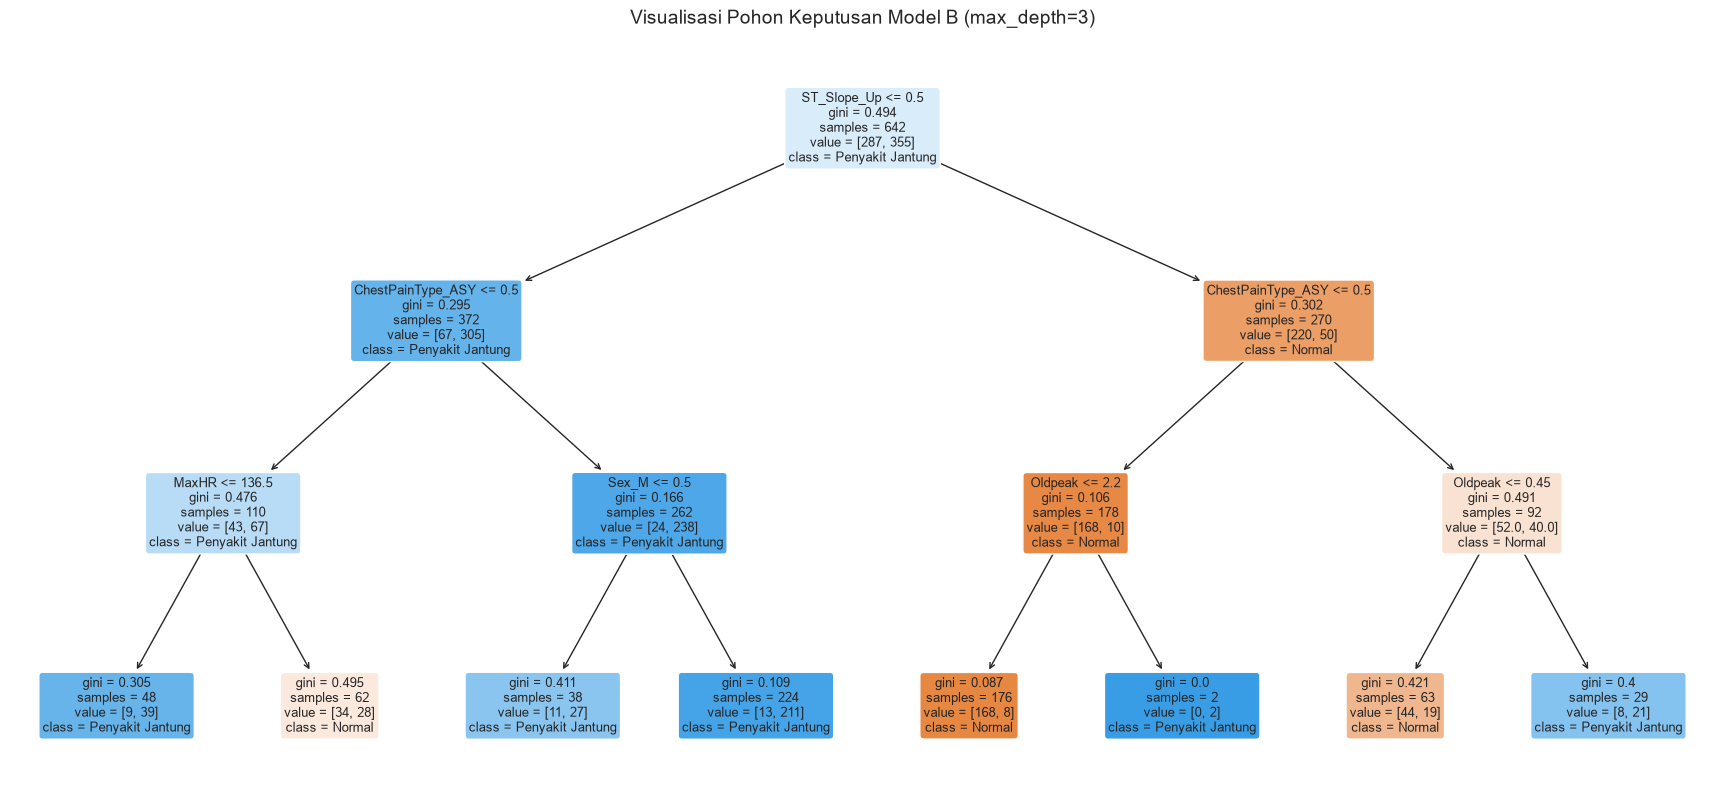

In [15]:
# Nama fitur setelah One-Hot Encoding
feat_names = [n.replace("num__", "").replace("cat__", "")
              for n in modelB.named_steps["prep"].get_feature_names_out()]

plt.figure(figsize=(22, 10))
plot_tree(clfB, feature_names=feat_names, class_names=["Normal", "Penyakit Jantung"],
          filled=True, rounded=True, fontsize=9)
plt.title(f"Visualisasi Pohon Keputusan Model B (max_depth={best_depth})", fontsize=14)
plt.show()

In [16]:
# Aturan dalam bentuk teks (untuk menerjemahkan jalur akar -> daun menjadi aturan jika-maka)
print(export_text(clfB, feature_names=feat_names, show_weights=True))

|--- ST_Slope_Up <= 0.50
|   |--- ChestPainType_ASY <= 0.50
|   |   |--- MaxHR <= 136.50
|   |   |   |--- weights: [9.00, 39.00] class: 1
|   |   |--- MaxHR >  136.50
|   |   |   |--- weights: [34.00, 28.00] class: 0
|   |--- ChestPainType_ASY >  0.50
|   |   |--- Sex_M <= 0.50
|   |   |   |--- weights: [11.00, 27.00] class: 1
|   |   |--- Sex_M >  0.50
|   |   |   |--- weights: [13.00, 211.00] class: 1
|--- ST_Slope_Up >  0.50
|   |--- ChestPainType_ASY <= 0.50
|   |   |--- Oldpeak <= 2.20
|   |   |   |--- weights: [168.00, 8.00] class: 0
|   |   |--- Oldpeak >  2.20
|   |   |   |--- weights: [0.00, 2.00] class: 1
|   |--- ChestPainType_ASY >  0.50
|   |   |--- Oldpeak <= 0.45
|   |   |   |--- weights: [44.00, 19.00] class: 0
|   |   |--- Oldpeak >  0.45
|   |   |   |--- weights: [8.00, 21.00] class: 1



ST_Slope          0.706
ChestPainType     0.175
Oldpeak           0.060
MaxHR             0.039
Sex               0.019
Age               0.000
RestingBP         0.000
Cholesterol       0.000
FastingBS         0.000
RestingECG        0.000
ExerciseAngina    0.000
dtype: float64


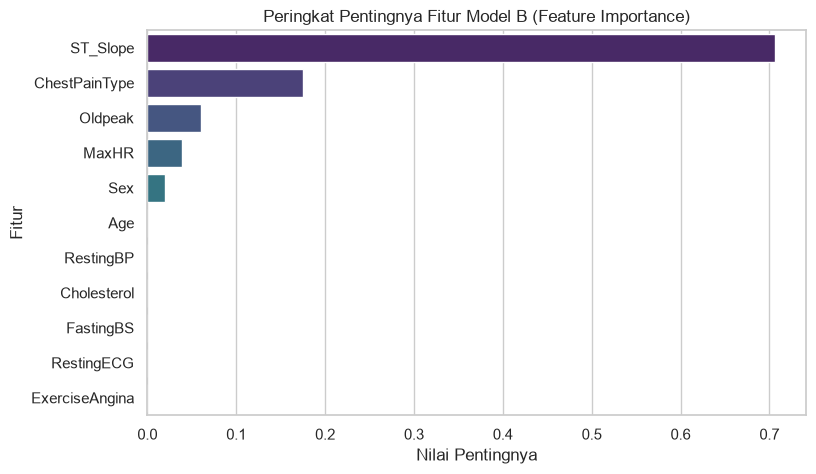

In [17]:
# Feature importance (digabung per fitur asli)
imp = pd.Series(clfB.feature_importances_, index=feat_names)
orig = {}
for n, v in imp.items():
    base = next((c for c in cat_feats if n.startswith(c + "_")), n)
    orig[base] = orig.get(base, 0) + v
orig = pd.Series(orig).sort_values(ascending=False)
print(orig.round(3))

plt.figure(figsize=(8.5, 5))
sns.barplot(x=orig.values, y=orig.index, hue=orig.index, palette="viridis", legend=False)
plt.title("Peringkat Pentingnya Fitur Model B (Feature Importance)")
plt.xlabel("Nilai Pentingnya"); plt.ylabel("Fitur")
plt.show()

## 7. Penyimpanan Model dengan Joblib

In [18]:
joblib.dump(modelB, "model/model_decision_tree.joblib")

# Uji muat ulang model dan prediksi satu contoh pasien
model_muat = joblib.load("model/model_decision_tree.joblib")
contoh = pd.DataFrame([{
    "Age": 54, "Sex": "M", "ChestPainType": "ASY", "RestingBP": 140, "Cholesterol": np.nan,
    "FastingBS": 0, "RestingECG": "Normal", "MaxHR": 110, "ExerciseAngina": "Y",
    "Oldpeak": 2.0, "ST_Slope": "Flat"}])
print("Prediksi:", model_muat.predict(contoh)[0], "| Probabilitas:", model_muat.predict_proba(contoh)[0].round(3))

Prediksi: 1 | Probabilitas: [0.058 0.942]


## 8. Kesimpulan
Isi kesimpulan sesuai hasil yang tampil di notebook Anda: perbandingan akurasi data latih vs data uji pada Model A dan Model B, fitur paling penting, serta jalur keputusan yang dapat diterjemahkan menjadi aturan jika-maka.

**Referensi:** Soriano, F. (2021). *Heart failure prediction dataset* [Data set]. Kaggle. https://www.kaggle.com/datasets/fedesoriano/heart-failure-prediction